# 01 — Keşifsel veri analizi (EDA)

**Amaç:** Veri setini tanımak, hatalı kayıtları ve temizlik eşiklerini belirlemek, hedef değişkenle
ilişkileri incelemek ve modelleme kararlarına temel oluşturmak.

**Veri:** [Loan Approval Classification Dataset](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data)
(Ta-wei Lo, Apache 2.0).

> `person_gender` modele **girmeyecek**; burada yalnızca betimsel olarak ve ileride adalet denetimi
> için incelenir.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from loan_ml.data import (
    DEFAULT_FLAG,
    EDUCATION_ORDER,
    MAX_AGE,
    MAX_EMP_EXP,
    NUMERIC_FEATURES,
    SENSITIVE,
    TARGET,
    clean,
    file_sha256,
    load_raw,
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 110

## 1. Genel bakış

In [2]:
df = load_raw()
print("Boyut:", df.shape)
print("SHA-256 (ilk 16):", file_sha256()[:16])
print("Eksik değer:", int(df.isna().sum().sum()))
print("Tekrarlanan satır:", int(df.duplicated().sum()))
df.head()

Boyut: (45000, 14)
SHA-256 (ilk 16): 67cca604cd71cbd6
Eksik değer: 0
Tekrarlanan satır: 0


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.000,female,Master,"71,948.000",0,RENT,"35,000.000",PERSONAL,16.020,0.490,3.000,561,No,1
1,21.000,female,High School,"12,282.000",0,OWN,"1,000.000",EDUCATION,11.140,0.080,2.000,504,Yes,0
2,25.000,female,High School,"12,438.000",3,MORTGAGE,"5,500.000",MEDICAL,12.870,0.440,3.000,635,No,1
3,23.000,female,Bachelor,"79,753.000",0,RENT,"35,000.000",MEDICAL,15.230,0.440,2.000,675,No,1
4,24.000,male,Master,"66,135.000",1,RENT,"35,000.000",MEDICAL,14.270,0.530,4.000,586,No,1


In [3]:
df.dtypes.to_frame("dtype").T

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
dtype,float64,str,str,float64,int64,str,float64,str,float64,float64,float64,int64,str,int64


In [4]:
df[NUMERIC_FEATURES].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
person_age,"45,000.000",27.764,6.045,20.000,21.000,24.000,26.000,30.000,48.000,144.000
person_income,"45,000.000","80,319.053","80,422.499","8,000.000","17,875.950","47,204.000","67,048.000","95,789.250","271,450.060","7,200,766.000"
person_emp_exp,"45,000.000",5.410,6.064,0.000,0.000,1.000,4.000,8.000,26.000,125.000
loan_amnt,"45,000.000","9,583.158","6,314.887",500.000,"1,138.870","5,000.000","8,000.000","12,237.250","28,390.340","35,000.000"
loan_int_rate,"45,000.000",11.007,2.979,5.420,5.420,8.590,11.010,12.990,18.250,20.000
loan_percent_income,"45,000.000",0.140,0.087,0.000,0.020,0.070,0.120,0.190,0.400,0.660
cb_person_cred_hist_length,"45,000.000",5.867,3.880,2.000,2.000,3.000,4.000,8.000,17.000,30.000
credit_score,"45,000.000",632.609,50.436,390.000,497.000,601.000,640.000,670.000,724.000,850.000


## 2. Hedef değişken

`loan_status`: 1 = onay, 0 = ret.

,adet,oran
loan_status,,
Ret (0),35000,0.778
Onay (1),10000,0.222


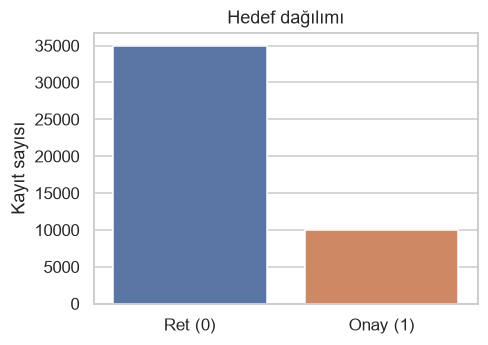

In [5]:
target_counts = df[TARGET].value_counts().rename({0: "Ret (0)", 1: "Onay (1)"})
display(pd.DataFrame({"adet": target_counts, "oran": target_counts / len(df)}))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax, hue=target_counts.index, legend=False)
ax.set(title="Hedef dağılımı", xlabel="", ylabel="Kayıt sayısı")
plt.show()

Sınıflar dengesiz: accuracy tek başına anlamlı bir metrik değildir. Ana metrikler ROC-AUC, PR-AUC
ve F1 olacaktır.

## 3. Kritik bulgu: geçmiş temerrüt kaydı

In [6]:
ct = pd.crosstab(df[DEFAULT_FLAG], df[TARGET], margins=True)
ct.columns = ["Ret (0)", "Onay (1)", "Toplam"]
ct["Onay oranı"] = ct["Onay (1)"] / ct["Toplam"]
ct

,Ret (0),Onay (1),Toplam,Onay oranı
previous_loan_defaults_on_file,,,,
No,12142,10000,22142,0.452
Yes,22858,0,22858,0.000
All,35000,10000,45000,0.222


`previous_loan_defaults_on_file = Yes` olan kayıtların **tamamı** ret. Yani veri setinin yaklaşık
yarısı tek bir kolonla kusursuz ayrışıyor. Sonuçları:

- Genel metrikler (özellikle accuracy ve ROC-AUC) bu kolay yarı yüzünden şişer.
- Modelin gerçek ayırt etme gücü yalnızca **`No` alt grubunda** görülür. Bu yüzden bundan sonraki
  tüm değerlendirmelerde metrikler hem genel hem de `No` alt grubu için raporlanır.

## 4. Hatalı kayıtlar ve temizlik eşikleri

Yaş > 70 olan değerler: [73.0, 73.0, 73.0, 76.0, 78.0, 80.0, 84.0, 94.0, 109.0, 116.0, 123.0, 123.0, 144.0, 144.0, 144.0]
İş tecrübesi > 45 olan değerler: [46, 46, 47, 47, 47, 47, 47, 48, 48, 49, 49, 50, 50, 57, 58, 61, 62, 76, 85, 93, 100, 101, 121, 124, 125]


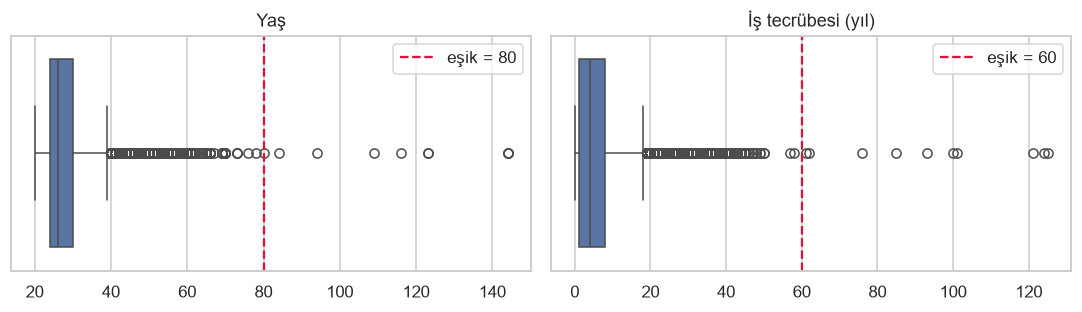

In [7]:
print("Yaş > 70 olan değerler:", sorted(df.loc[df.person_age > 70, "person_age"].tolist()))
print("İş tecrübesi > 45 olan değerler:", sorted(df.loc[df.person_emp_exp > 45, "person_emp_exp"].tolist()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=df.person_age, ax=axes[0])
axes[0].axvline(MAX_AGE, color="crimson", ls="--", label=f"eşik = {MAX_AGE}")
axes[0].set(title="Yaş", xlabel="")
axes[0].legend()
sns.boxplot(x=df.person_emp_exp, ax=axes[1])
axes[1].axvline(MAX_EMP_EXP, color="crimson", ls="--", label=f"eşik = {MAX_EMP_EXP}")
axes[1].set(title="İş tecrübesi (yıl)", xlabel="")
axes[1].legend()
plt.tight_layout()
plt.show()

In [8]:
bad = df[(df.person_age > MAX_AGE) | (df.person_emp_exp > MAX_EMP_EXP)]
print(f"Çıkarılacak satır: {len(bad)}")
bad[["person_age", "person_emp_exp", "person_income", "cb_person_cred_hist_length", TARGET]]

Çıkarılacak satır: 10


,person_age,person_emp_exp,person_income,cb_person_cred_hist_length,loan_status
81,144.000,125,"300,616.000",3.000,0
183,144.000,121,"241,424.000",2.000,0
575,123.000,101,"97,140.000",3.000,0
747,123.000,100,"94,723.000",4.000,0
32297,144.000,124,"7,200,766.000",25.000,0
32416,94.000,76,"29,738.000",27.000,0
32422,80.000,62,"77,894.000",25.000,0
32506,84.000,61,"114,705.000",24.000,0
37930,116.000,93,"5,545,545.000",24.000,0
38113,109.000,85,"5,556,399.000",22.000,0


Yaş ve iş tecrübesi tutarlılığı: iş tecrübesi, yaştan en az ~15–18 yıl küçük olmalıdır.

In [9]:
gap = df.person_age - df.person_emp_exp
print("yaş − tecrübe  min / medyan / max:", gap.min(), gap.median(), gap.max())
print("tecrübe > yaş − 15 olan satır:", int((df.person_emp_exp > df.person_age - 15).sum()))
print("tecrübe > yaş − 18 olan satır:", int((df.person_emp_exp > df.person_age - 18).sum()))

yaş − tecrübe  min / medyan / max: 18.0 22.0 30.0
tecrübe > yaş − 15 olan satır: 0
tecrübe > yaş − 18 olan satır: 0


Veride iş tecrübesi her zaman `yaş − 18` değerinden küçük veya eşittir. Planda API doğrulaması için
öngörülen `person_emp_exp ≤ person_age − 15` kuralı veriyle çelişmez; `yaş − 18` daha sıkı ve veriye
daha uygun bir sınırdır (Faz 3'te karar verilecek).

In [10]:
data = clean(df)
print(f"Temizlik sonrası: {len(data):,} satır ({len(df) - len(data)} satır çıkarıldı)")
print(f"Onay oranı: {data[TARGET].mean():.4f}")
print("Yaş aralığı:", data.person_age.min(), "–", data.person_age.max())
print("İş tecrübesi aralığı:", data.person_emp_exp.min(), "–", data.person_emp_exp.max())

Temizlik sonrası: 44,990 satır (10 satır çıkarıldı)
Onay oranı: 0.2223
Yaş aralığı: 20.0 – 78.0
İş tecrübesi aralığı: 0 – 58


## 5. Türetilmiş kolon: `loan_percent_income`

In [11]:
ratio = df.loan_amnt / df.person_income
print("round(loan_amnt / person_income, 2) ile eşleşen satır oranı:",
      float((np.abs(ratio.round(2) - df.loan_percent_income) < 1e-9).mean()))
print("Ham oran ile en büyük mutlak fark:", float((ratio - df.loan_percent_income).abs().max()))

round(loan_amnt / person_income, 2) ile eşleşen satır oranı: 0.9999111111111111
Ham oran ile en büyük mutlak fark: 0.00503013444598982


Kolon, `loan_amnt / person_income` değerinin **iki ondalığa yuvarlanmış** halidir (yalnızca birkaç
satırda yuvarlama sınırında 0,01'lik fark vardır). Eğitim/servis
uyumu için backend bu değeri aynı şekilde (`round(loan_amnt / person_income, 2)`) hesaplayacaktır.

## 6. Sayısal değişkenlerin dağılımı

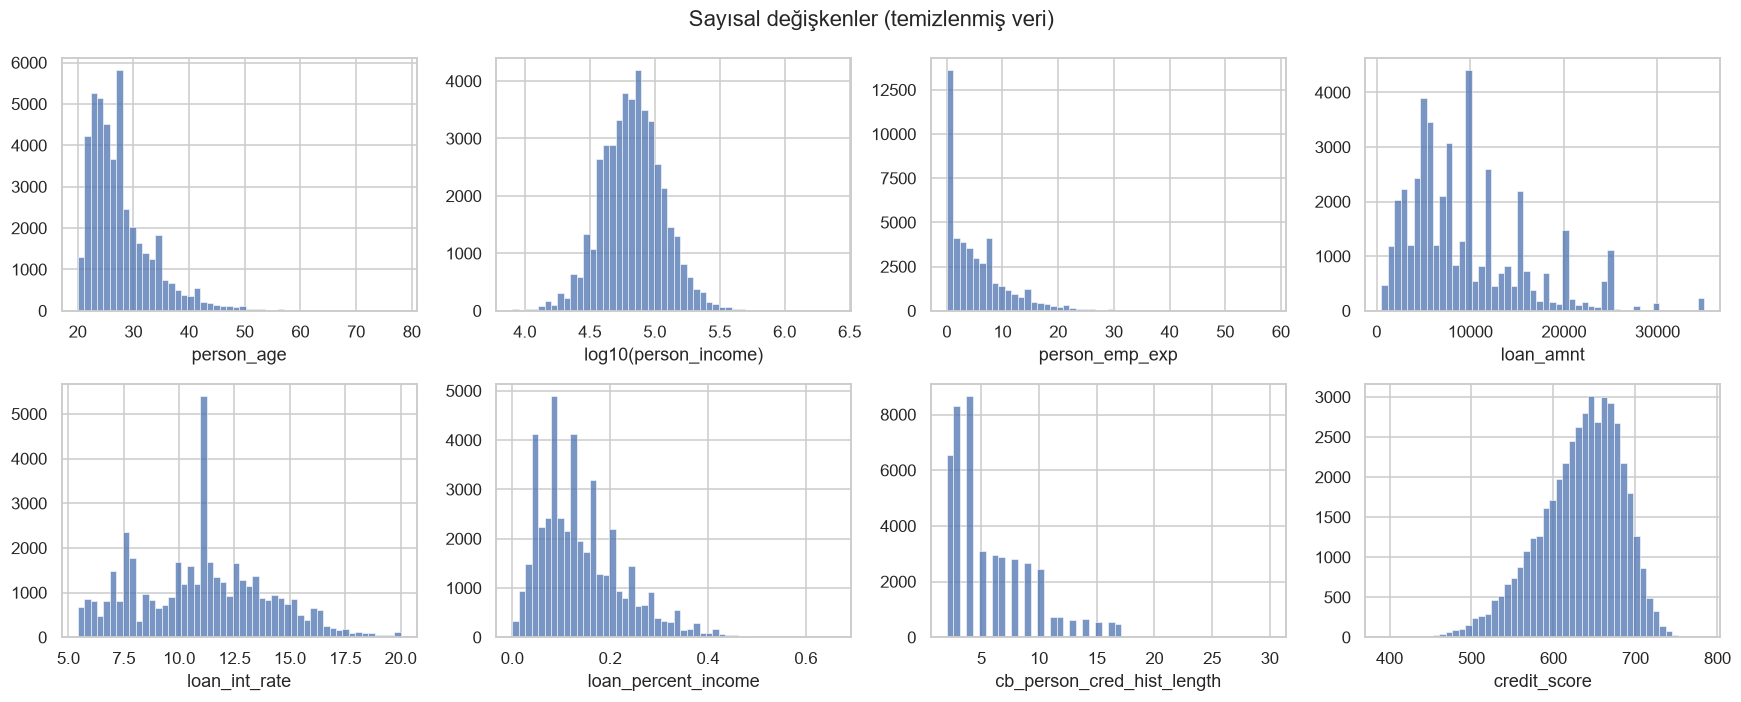

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    series = data[col]
    if col == "person_income":
        sns.histplot(np.log10(series), bins=50, ax=ax)
        ax.set_xlabel("log10(person_income)")
    else:
        sns.histplot(series, bins=50, ax=ax)
    ax.set_ylabel("")
plt.suptitle("Sayısal değişkenler (temizlenmiş veri)")
plt.tight_layout()
plt.show()

In [13]:
data[NUMERIC_FEATURES].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).T

,0.010,0.050,0.500,0.950,0.990
person_age,21.000,22.000,26.000,39.000,48.000
person_income,"17,875.450","28,363.700","67,045.500","166,698.600","271,268.820"
person_emp_exp,0.000,0.000,4.000,17.000,26.000
loan_amnt,"1,137.570","2,000.000","8,000.000","24,000.000","28,393.740"
loan_int_rate,5.420,6.170,11.010,16.000,18.250
loan_percent_income,0.020,0.030,0.120,0.310,0.400
cb_person_cred_hist_length,2.000,2.000,4.000,14.000,17.000
credit_score,497.000,539.000,640.000,703.000,724.000


- Veri **genç profile** ağırlıklı; yaşlı profillerde model daha az güvenilir olacaktır.
- Gelir güçlü biçimde sağa çarpık; doğrusal modelde log dönüşümü gerekir (ağaç modellerinde gerekmez).
- p1–p99 aralıkları, canlıda "düşük güven" uyarısı için `metadata.json`'a yazılacaktır.

## 7. Hedefle ilişkiler

Geçmiş temerrüt kaydı olanların tamamı ret olduğu için, ilişkiler **`No` alt grubunda** incelenir;
aksi halde her şey o kolonun gölgesinde kalır.

In [14]:
no_default = data[data[DEFAULT_FLAG] == "No"]
print(f"`No` alt grubu: {len(no_default):,} satır, onay oranı {no_default[TARGET].mean():.4f}")

corr = pd.DataFrame({
    "tüm veri": data[NUMERIC_FEATURES + [TARGET]].corr(method="spearman")[TARGET],
    "`No` alt grubu": no_default[NUMERIC_FEATURES + [TARGET]].corr(method="spearman")[TARGET],
}).drop(index=TARGET).sort_values("`No` alt grubu", key=abs, ascending=False)
corr.style.format("{:+.3f}").background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6)

`No` alt grubu: 22,135 satır, onay oranı 0.4518


,tüm veri,`No` alt grubu
loan_percent_income,+0.324,+0.392
loan_int_rate,+0.311,+0.371
person_income,-0.275,-0.334
credit_score,-0.008,-0.178
loan_amnt,+0.087,+0.104
person_age,-0.030,-0.064
person_emp_exp,-0.027,-0.064
cb_person_cred_hist_length,-0.020,-0.048


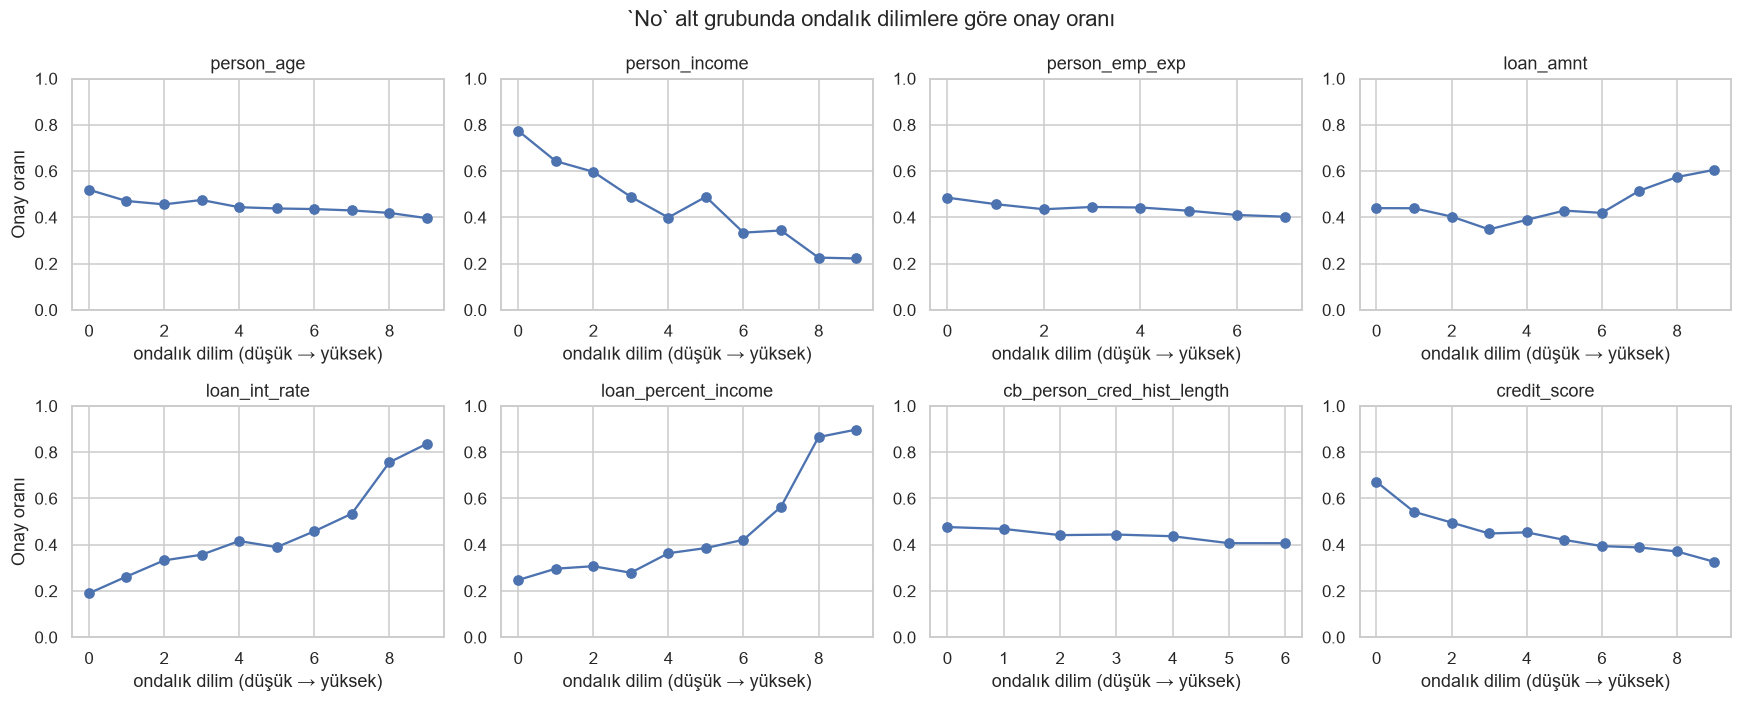

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    binned = pd.qcut(no_default[col], q=10, duplicates="drop")
    rate = no_default.groupby(binned, observed=True)[TARGET].mean()
    ax.plot(range(len(rate)), rate.values, marker="o")
    ax.set(title=col, xlabel="ondalık dilim (düşük → yüksek)", ylim=(0, 1))
axes[0, 0].set_ylabel("Onay oranı")
axes[1, 0].set_ylabel("Onay oranı")
plt.suptitle("`No` alt grubunda ondalık dilimlere göre onay oranı")
plt.tight_layout()
plt.show()

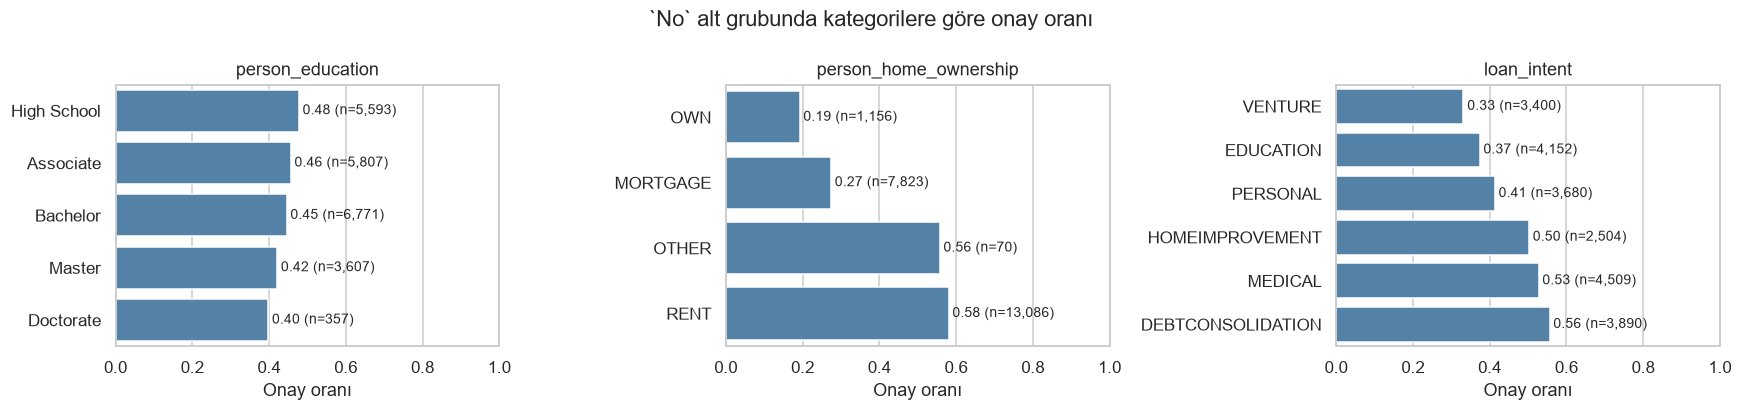

In [16]:
cat_cols = ["person_education", "person_home_ownership", "loan_intent"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, cat_cols):
    order = EDUCATION_ORDER if col == "person_education" else None
    rate = no_default.groupby(col)[TARGET].agg(["mean", "size"])
    rate = rate.loc[order] if order else rate.sort_values("mean")
    sns.barplot(x=rate["mean"].values, y=rate.index, ax=ax, color="steelblue")
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(m + 0.01, i, f"{m:.2f} (n={n:,})", va="center", fontsize=9)
    ax.set(title=col, xlabel="Onay oranı", ylabel="", xlim=(0, 1))
plt.suptitle("`No` alt grubunda kategorilere göre onay oranı")
plt.tight_layout()
plt.show()

### ⚠️ Etiketin yönü sezgiye ters

Yukarıdaki ilişkiler gerçek bir kredi onay sürecinden beklenenin **tersidir**:

- **Faiz oranı** ve **kredi/gelir oranı** arttıkça "onay" oranı **artıyor**.
- **Gelir** arttıkça "onay" oranı **düşüyor**.
- **Kiracılar**, ev sahiplerinden çok daha sık "onaylanıyor".
- **Kredi skoru** arttıkça "onay" oranı hafifçe düşüyor.

Bu örüntü, temerrüt (geri ödememe) riskini modelleyen veri setlerinin tipik imzasıdır. Veri seti
sentetiktir ve Kaggle'daki açıklamasına göre bilinen bir kredi riski veri setinden türetilmiştir;
o kaynakta `loan_status = 1` **temerrüt** anlamına gelir. Burada aynı kolon "1 = onay" olarak
belgelenmiştir, ancak özelliklerle ilişkisi temerrüt etiketi gibi davranmaktadır.

**Bu notebook serisinde etiket, veri setinin belgelendiği haliyle (1 = onay) kullanılır.** Ancak
ürün açısından sonucu önemlidir: model, "daha yüksek faiz ve daha düşük gelir → daha yüksek onay
olasılığı" öğrenecektir. Bu, ürün kararı gerektiren açık bir konudur (bkz. `PROJE_PLANI.md`, Bölüm 12).

In [17]:
direction = pd.DataFrame({
    "düşük dilim (ilk %20)": [
        no_default.loc[no_default[c] <= no_default[c].quantile(0.2), TARGET].mean()
        for c in ["person_income", "loan_int_rate", "loan_percent_income", "credit_score"]
    ],
    "yüksek dilim (son %20)": [
        no_default.loc[no_default[c] >= no_default[c].quantile(0.8), TARGET].mean()
        for c in ["person_income", "loan_int_rate", "loan_percent_income", "credit_score"]
    ],
}, index=["person_income", "loan_int_rate", "loan_percent_income", "credit_score"])
direction.style.format("{:.3f}").set_caption("`No` alt grubunda onay oranı")

,düşük dilim (ilk %20),yüksek dilim (son %20)
person_income,0.709,0.224
loan_int_rate,0.226,0.797
loan_percent_income,0.267,0.869
credit_score,0.607,0.350


## 8. Değişkenler arası korelasyon

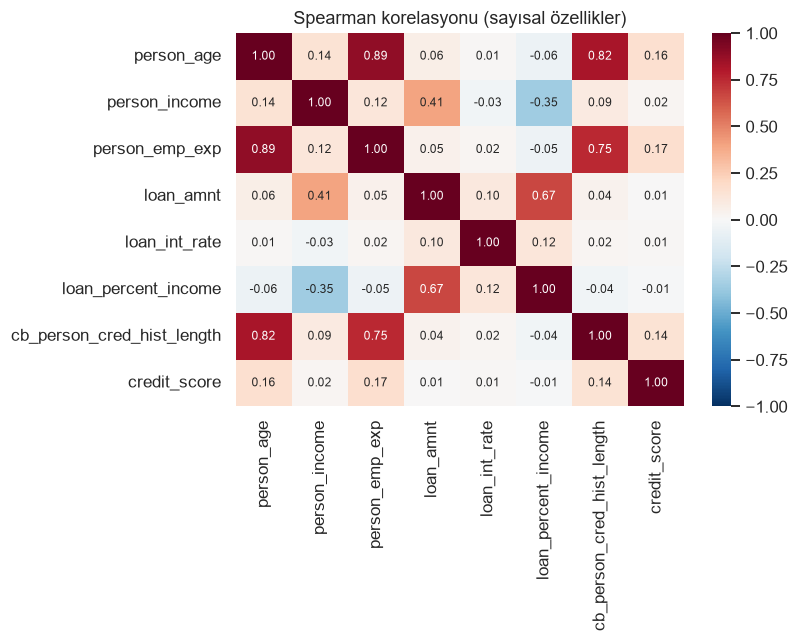

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(data[NUMERIC_FEATURES].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman korelasyonu (sayısal özellikler)")
plt.tight_layout()
plt.show()

Yaş, iş tecrübesi ve kredi geçmişi süresi birbirleriyle yüksek korelasyonludur. Ağaç tabanlı
modeller için sorun değildir; Logistic Regression katsayılarını yorumlarken dikkate alınmalıdır.

## 9. Cinsiyet (yalnızca betimsel)

In [19]:
gender = pd.DataFrame({
    "adet": data.groupby(SENSITIVE).size(),
    "onay oranı (tüm veri)": data.groupby(SENSITIVE)[TARGET].mean(),
    "onay oranı (`No` alt grubu)": no_default.groupby(SENSITIVE)[TARGET].mean(),
})
gender

,adet,onay oranı (tüm veri),onay oranı (`No` alt grubu)
person_gender,,,
female,20157,0.223,0.452
male,24833,0.222,0.452


Cinsiyet kolonu model girdisi **olmayacak**. Dolaylı etki olup olmadığı test setinde, model
tahminleri üzerinden `04_evaluation_explainability.ipynb` içinde denetlenecektir.

## 10. Sonuçlar ve modelleme kararları

| Konu | Karar |
|---|---|
| Temizlik | `person_age > 80` veya `person_emp_exp > 60` olan satırlar çıkarılır |
| Model girdileri | 12 özellik; `person_gender` hariç |
| `loan_percent_income` | `round(loan_amnt / person_income, 2)`; canlıda backend hesaplar |
| Gelir | Doğrusal modelde log dönüşümü; ağaç modellerinde ham |
| Metrikler | ROC-AUC, PR-AUC, F1, precision, recall, Brier — **genel + `No` alt grubu** |
| Bölme | %70 / %15 / %15, hedefe göre katmanlı, `random_state=42` |
| Etiket | Belgelendiği gibi 1 = onay; ancak yönü sezgiye ters — **ürün kararı bekliyor** |